# Supermarket dashboard — exploratory analysis
Source: [Fares Ashraf, Kaggle, version 2](https://www.kaggle.com/datasets/faresashraf1001/supermarket-sales).
The data card describes supermarket transactions in Myanmar; collection provenance and real-versus-synthetic status are not independently established. Inspect the exact source file before designing the dashboard.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
df=pd.read_csv('data/supermarket_sales.csv')
df['Date']=pd.to_datetime(df['Date'],format='%m/%d/%Y')
print('Shape:',df.shape,'Period:',df.Date.min(),df.Date.max())
print('Duplicate invoices:',df['Invoice ID'].duplicated().sum())
display(df.dtypes.rename('dtype').to_frame())
display(df.isna().sum().rename('missing').to_frame())
display(df.describe(include='all'))
display(df.groupby(['Branch','City']).size().rename('transactions').to_frame())
assert df.shape==(1000,17)
assert df['Invoice ID'].is_unique
assert df.isna().sum().sum()==0
assert np.allclose(df.Sales,df.cogs+df['Tax 5%'])
assert np.allclose(df['gross income'],df['Tax 5%'])
assert np.allclose(df.cogs,df['Unit price']*df.Quantity)
print('Arithmetic checks passed. Gross income equals tax; do not use it as profit.')

Shape: (1000, 17) Period: 2019-01-01 00:00:00 2019-03-30 00:00:00
Duplicate invoices: 0


,dtype
Invoice ID,str
Branch,str
City,str
Customer type,str
Gender,str
Product line,str
Unit price,float64
Quantity,int64
Tax 5%,float64
Sales,float64


,missing
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
count,1000,1000,1000,1000,1000,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000,1000,1000,1000.00000,1000.000000,1000.000000,1000.00000
unique,1000,3,3,2,2,6,NaN,NaN,NaN,NaN,NaN,506,3,NaN,NaN,NaN,NaN
top,750-67-8428,Alex,Yangon,Member,Female,Fashion accessories,NaN,NaN,NaN,NaN,NaN,7:48:00 PM,Ewallet,NaN,NaN,NaN,NaN
freq,1,340,340,565,571,178,NaN,NaN,NaN,NaN,NaN,7,345,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,55.672130,5.510000,15.379369,322.966749,2019-02-14 00:05:45.600000,NaN,NaN,307.58738,4.761905,15.379369,6.97270
min,NaN,NaN,NaN,NaN,NaN,NaN,10.080000,1.000000,0.508500,10.678500,2019-01-01 00:00:00,NaN,NaN,10.17000,4.761905,0.508500,4.00000
25%,NaN,NaN,NaN,NaN,NaN,NaN,32.875000,3.000000,5.924875,124.422375,2019-01-24 00:00:00,NaN,NaN,118.49750,4.761905,5.924875,5.50000
50%,NaN,NaN,NaN,NaN,NaN,NaN,55.230000,5.000000,12.088000,253.848000,2019-02-13 00:00:00,NaN,NaN,241.76000,4.761905,12.088000,7.00000
75%,NaN,NaN,NaN,NaN,NaN,NaN,77.935000,8.000000,22.445250,471.350250,2019-03-08 00:00:00,NaN,NaN,448.90500,4.761905,22.445250,8.50000
max,NaN,NaN,NaN,NaN,NaN,NaN,99.960000,10.000000,49.650000,1042.650000,2019-03-30 00:00:00,NaN,NaN,993.00000,4.761905,49.650000,10.00000


,,transactions
Branch,City,
Alex,Yangon,340
Cairo,Mandalay,332
Giza,Naypyitaw,328


Arithmetic checks passed. Gross income equals tax; do not use it as profit.


The source's Branch labels (Alex/Cairo/Giza) conflict with its Myanmar city names; I use City as the store key and preserve the raw data. Sales is tax-inclusive. Complete fields do not prove full population coverage. The apparent gross-income field equals tax, so profit is excluded from the dashboard.

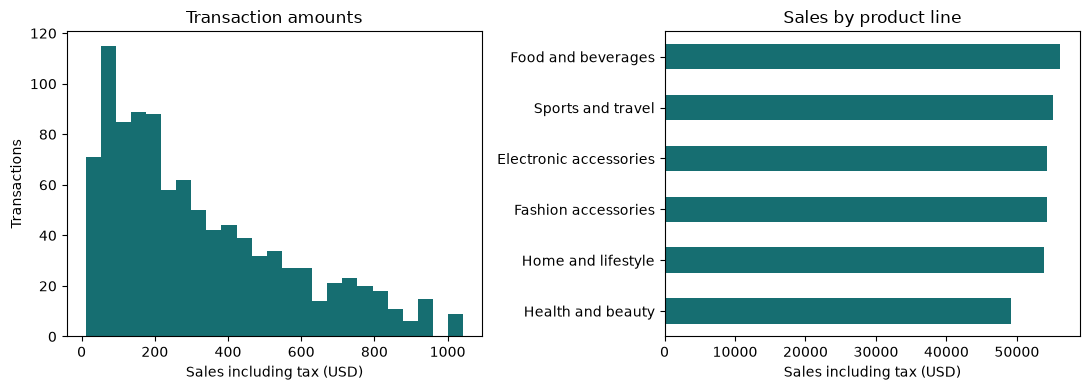

Total sales: 322966.75 Average transaction: 322.97


,Sales distribution
0.00,10.678500
0.25,124.422375
0.50,253.848000
0.75,471.350250
0.95,822.496500
1.00,1042.650000


In [2]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].hist(df.Sales,bins=25,color='#166e71');axs[0].set(title='Transaction amounts',xlabel='Sales including tax (USD)',ylabel='Transactions')
df.groupby('Product line').Sales.sum().sort_values().plot.barh(ax=axs[1],color='#166e71')
axs[1].set(title='Sales by product line',xlabel='Sales including tax (USD)',ylabel='')
fig.tight_layout();plt.show()
print('Total sales:',round(df.Sales.sum(),2),'Average transaction:',round(df.Sales.mean(),2))
display(df.Sales.quantile([0,.25,.5,.75,.95,1]).rename('Sales distribution').to_frame())

Transaction amounts are dispersed, so I retain both transaction count and mean amount to explain changes in sales. A product-line comparison can direct a follow-up. Payment/gender charts would not directly change that follow-up and are cut.

,sales,transactions,complete_span
Week,,,
2018-12-31,17543.39,55,False
2019-01-07,24461.20,73,True
2019-01-14,28693.36,82,True
2019-01-21,29286.88,93,True
2019-01-28,28360.45,83,True
2019-02-04,27101.83,92,True
2019-02-11,25563.59,72,True
2019-02-18,17328.66,60,True
2019-02-25,29219.72,87,True


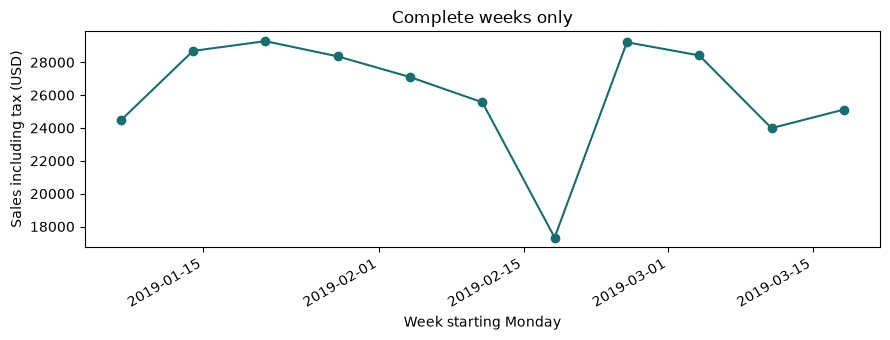

,sales,transactions
City,,
Mandalay,106197.67,332
Naypyitaw,110568.71,328
Yangon,106200.37,340


In [3]:
df['Week']=df.Date.dt.to_period('W-SUN').dt.start_time
weekly=df.groupby('Week').agg(sales=('Sales','sum'),transactions=('Invoice ID','nunique'))
weekly['complete_span']=(weekly.index>=df.Date.min()) & ((weekly.index+pd.Timedelta(days=6))<=df.Date.max())
display(weekly.round(2))
full=weekly[weekly.complete_span]
fig,ax=plt.subplots(figsize=(9,3.5))
ax.plot(full.index,full.sales,marker='o',color='#166e71')
ax.set(title='Complete weeks only',xlabel='Week starting Monday',ylabel='Sales including tax (USD)')
fig.autofmt_xdate();fig.tight_layout();plt.show()
display(df.groupby('City').agg(sales=('Sales','sum'),transactions=('Invoice ID','nunique')).round(2))

The first and last weeks are partial and excluded from selectable review periods. Comparisons use the immediately preceding complete calendar week; the first full week has no valid predecessor within this snapshot, so no change is shown. The production refresh is nightly, while the manager reviews Monday mornings; a >15% sales fall prompts investigation, with that threshold explicitly provisional.